# 04 · Model training, comparison and evaluation

<a id="12-SETUP"></a>
<a id="SETUP"></a>
### `SETUP` · Setup: component environment and immutable evidence

In [1]:
# Code block: 12-SETUP
from pathlib import Path
import sys
WORKSPACE = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'source/bpdr_input').is_dir())
sys.path.insert(0, str(WORKSPACE / 'source'))
from bpdr_input.reporting.notebook_setup import prepare, load_catalogs, show
globals().update(prepare(WORKSPACE))
show(pd.DataFrame([{'check': 'Saved model and evidence identities', 'result': 'PASS',
                    'recorded_run': RUN.name}]))


,check,result,recorded_run
0,Saved model and evidence identities,PASS,b4c64c3b861a48c494c092458716b4fc


<a id="12-CONTEXT"></a>
<a id="CONTEXT"></a>
### `CONTEXT` · Load local split catalogs and common helper names

In [2]:
# Code block: 12-CONTEXT
globals().update(load_catalogs(RUN, MANIFEST))
show(pd.DataFrame([
    dict(split=s, recordings=len(SOURCE_RECORDS[s]), singers=len(groups[s]),
         intervention_attempts=len(PAIRS[s])) for s in SPLITS
]))


,split,recordings,singers,intervention_attempts
0,train,16,8,64
1,calibration,4,2,16
2,pilot_evaluation,4,2,16


<a id="TRANSFORMER-HISTORY"></a>
### `TRANSFORMER-HISTORY` · Historical Transformer and MLP evidence

In [3]:
# Code block: TRANSFORMER-HISTORY
from bpdr_input.reporting.bpdr_showcase import load_model as load_transformer
transformer_card = read_json(WORKSPACE / 'selected_model/model.json')
transformer_path = WORKSPACE / 'selected_model' / transformer_card['checkpoint']

historical_transformer, _, transformer_width = load_transformer(transformer_path)
transformer_description = historical_transformer.describe()
small_run = Path(read_json(WORKSPACE / 'results/small_real_pilot/current.json')['path'])
small_evidence = read_json(small_run / 'evidence.json')
historical_rows = []
for condition, row in small_evidence['results'].items():
    for dataset, result in row['development']['by_dataset'].items():
        historical_rows.append(dict(model='Earlier LocalContextMLP', condition=condition, dataset=dataset, correction_MAE_cents=result['correction_mae'], unchanged_baseline_cents=result['zero_mae'], original_prediction_abs_cents=result['unshifted_alteration'], criteria_passed=result['passes']))
show(pd.DataFrame([dict(model='Historical BPDR Transformer', **transformer_description)]))

,model,features,hidden,layers,heads,feed_forward,dropout,parameters
0,Historical BPDR Transformer,71,128,4,4,512,0.1000,802433


<a id="TRANSFORMER-HISTORY-3"></a>
#### Inspect the result

In [13]:
# Code block: TRANSFORMER-HISTORY-3
show(pd.DataFrame(transformer_results).round(6))

,model,dataset,variants,raw_correction_MAE,zero_baseline_MAE,median_response_gain,original_abs_proposal
0,Historical adapted BPDR Transformer,jamendo,285,19.6786,19.6842,0.0002,0.2382
1,Historical adapted BPDR Transformer,vocadito,19,29.9099,30.0000,0.0002,0.1714


<a id="TRANSFORMER-HISTORY-4"></a>
#### Inspect the result

In [14]:
#  TRANSFORMER-HISTORY-4
print('Historical adapted Transformer criteria passed:', adapted['results']['bpdr']['engineering_gate_passes'])
print('Earlier compact MLP pilot, shown separately:')
show(pd.DataFrame(historical_rows).round(4))

Historical adapted Transformer criteria passed: False
Earlier compact MLP pilot, shown separately:


,model,condition,dataset,correction_MAE_cents,unchanged_baseline_cents,original_prediction_abs_cents,criteria_passed
0,Earlier LocalContextMLP,augmentation_only,jamendo,14.7906,23.3333,2.3412,False
1,Earlier LocalContextMLP,augmentation_only,vocadito,29.1528,30.0000,2.3206,False
2,Earlier LocalContextMLP,frame_only,jamendo,14.8627,23.3333,2.1407,False
3,Earlier LocalContextMLP,frame_only,vocadito,29.7680,30.0000,2.0962,False
4,Earlier LocalContextMLP,bpdr,jamendo,14.1108,23.3333,2.4493,False
5,Earlier LocalContextMLP,bpdr,vocadito,30.1374,30.0000,2.1522,False


<a id="MODEL-LOAD"></a>
### `MODEL-LOAD` · ExtraTrees, gradient boosting and saved model parameters

In [15]:
# MODEL-LOAD
from bpdr_input.modeling.recovery_model import load_locked_diagnostic
MODEL, PAYLOAD = load_locked_diagnostic(CHECKPOINT)
ESTIMATOR = MODEL['estimator']
params = ESTIMATOR.get_params()
show(pd.DataFrame([{'parameter': k, 'saved_model_value': params[k]} for k in ['n_estimators', 'max_depth', 'min_samples_leaf', 'criterion', 'bootstrap', 'max_features', 'random_state', 'n_jobs']]))

,parameter,saved_model_value
0,n_estimators,96
1,max_depth,8
2,min_samples_leaf,12
3,criterion,squared_error
4,bootstrap,False
5,max_features,1.0000
6,random_state,339
7,n_jobs,2


<a id="MODEL-LOAD-3"></a>
#### Prepare or verify the next result

In [38]:
# Code block: MODEL-LOAD-3
print('Saved model type:', PAYLOAD['model_type'])
print('Saved operating settings:', PAYLOAD['operating_policy'])
print('Checkpoint SHA-256:', sha(CHECKPOINT))
print('Loading this diagnostic checkpoint does not assert that research gates passed.')

Saved model type: extra_trees
Saved operating settings: {'gain': 1.0, 'deadband_cents': 3.0}
Checkpoint SHA-256: 5bd8eef04ab45cc04ff8daed22c36cd7e862931c06f549b4a867de834df60449
Loading this diagnostic checkpoint does not assert that research gates passed.


The saved diagnostic model is ExtraTrees with 96 trees and 31 inputs. Its gain/deadband are locked settings. Loading the checkpoint does not turn failed validation into a pass.

<a id="MODEL-FIT-NEW"></a>
### `MODEL-FIT-NEW` · Train a new ExtraTrees model

In [19]:
# Code block: MODEL-FIT-NEW
from sklearn.ensemble import ExtraTreesRegressor
from threadpoolctl import threadpool_limits
from time import perf_counter
from bpdr_input.experiments.learning import notebook_training as training
# Replace this expression with True when deliberately fitting a fresh model.
TRAIN_NEW_MODEL = os.environ.get('BPDR_TRAIN_NOTEBOOK_MODEL', '0') == '1'
if TRAIN_NEW_MODEL:
    TRAINING_RUN, TRAINING_DECLARATION = training.begin_training(RUN)
else:
    TRAINING_RUN = training.active_training_run()
    TRAINING_DECLARATION = read_json(TRAINING_RUN / 'declaration.json')
show(pd.DataFrame([dict(action='FIT NEW' if TRAIN_NEW_MODEL else 'RELOAD SAVED',
                       training_run=TRAINING_RUN.name, fit_split='train')]))

,action,training_run,fit_split
0,RELOAD SAVED,2759404560ab4b559a633659d316bec0,train


<a id="MODEL-FIT-EXECUTE"></a>
### `MODEL-FIT-EXECUTE` · Fit on training rows only

In [20]:
# Code block: MODEL-FIT-EXECUTE
if TRAIN_NEW_MODEL:
    TRAINED_ESTIMATOR = ExtraTreesRegressor(**TRAINING_DECLARATION['model_parameters'])
    started = perf_counter()
    with threadpool_limits(limits=2):
        TRAINED_ESTIMATOR.fit(X_TRAIN, Y_TRAIN, sample_weight=W_TRAIN)
    FIT_RECEIPT = training.record_fit(TRAINING_RUN, TRAINED_ESTIMATOR,
        X_TRAIN, Y_TRAIN, W_TRAIN, perf_counter() - started)
else:
    FIT_RECEIPT = read_json(TRAINING_RUN / 'fit_receipt.json')
show(pd.DataFrame([{k: FIT_RECEIPT[k] for k in ['training_rows', 'features',
    'audited_pairs', 'training_singers', 'fit_seconds', 'train_weighted_mae_cents']}]))

,training_rows,features,audited_pairs,training_singers,fit_seconds,train_weighted_mae_cents
0,16842,31,43,7,0.9336,3.4879


<a id="MODEL-SAVE-CHECKPOINT"></a>
### `MODEL-SAVE-CHECKPOINT` · Save the fitted model


In [25]:
# Code block: MODEL-SAVE-CHECKPOINT
import joblib
TRAINING_CHECKPOINT = TRAINING_RUN / 'selected_model.joblib'
if TRAIN_NEW_MODEL:
    assert not TRAINING_CHECKPOINT.exists(), 'Never overwrite an existing model.'
    joblib.dump(dict(model=dict(kind='extra_trees', estimator=TRAINED_ESTIMATOR),
                     payload=training.checkpoint_payload(TRAINING_RUN)), TRAINING_CHECKPOINT)
    training.record_checkpoint(TRAINING_RUN)
show(pd.DataFrame([dict(checkpoint=str(TRAINING_CHECKPOINT),
                       sha256=sha(TRAINING_CHECKPOINT), saved=TRAINING_CHECKPOINT.is_file())]))

,checkpoint,sha256,saved
0,C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\model_recovery\notebook_training\2759404560ab4b559a633659d316bec0\selected_model.joblib,682f8e4839b80fa032a52769d6186ca349937e638ef4ddfd8bdf85278a3ec9b3,True


<a id="MODEL-VERIFY-DEMO"></a>
### `MODEL-VERIFY-DEMO` · Verify this checkpoint on delivered audio

In [26]:
# Code block: MODEL-VERIFY-DEMO
if TRAIN_NEW_MODEL:
    TRAINING_VERIFICATION = training.verify_for_demo(TRAINING_RUN)
else:
    TRAINING_VERIFICATION = read_json(TRAINING_RUN / 'rendered_verification.json')
show(pd.DataFrame([dict(shift_cents=r['cents'], singer=r['singer'],
    excluded=r.get('excluded'), outcome=r.get('outcome'),
    input_MAE=r.get('input_mae_cents'), output_MAE=r.get('output_mae_cents'),
    improved=r.get('verified_improvement')) for r in TRAINING_VERIFICATION['shifts']]))

,shift_cents,singer,excluded,outcome,input_MAE,output_MAE,improved
0,-30.0000,female6,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,—,—
1,-20.0000,female6,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,—,—
2,20.0000,female6,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,—,—
3,30.0000,female6,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,—,—
4,-30.0000,female6,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,—,—
5,-20.0000,female6,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,—,—
6,20.0000,female6,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,—,—
7,30.0000,female6,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,—,—
8,-30.0000,male6,—,VERIFIED_FIXTURE_CANDIDATE,30.8083,30.8083,False
9,-20.0000,male6,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,—,—


<a id="MODEL-ACCURACY"></a>
### `MODEL-ACCURACY` · Four checkpoints on common calibration examples

In [41]:
# Code block: MODEL-ACCURACY
comparison_pointer = read_json(WORKSPACE / 'results/model_comparison/current.json')
COMPARISON_RUN = Path(comparison_pointer['path']).resolve()
COMPARISON = read_json(COMPARISON_RUN / 'evidence.json')
sys.path.insert(0, str(WORKSPACE / 'tools'))
from compare_recovery_models import score_case as rescore_frozen_case, aggregate as aggregate_comparison
comparison_pairs = recovery_experiment.cached_pairs(PAIRS['calibration'])
model_names = { 'historical_transformer': 'BPDR Transformer', 'old_mlp': 'Frozen LocalContextMLP', 'hist_gradient_boosting': 'Histogram Gradient Boosting', 'extra_trees': 'ExtraTrees (demo)'}

<a id="MODEL-ACCURACY-2"></a>
#### Inspect the result

In [42]:
# Code block: MODEL-ACCURACY-2
comparison_rows = []
comparison_by_singer = []
from bpdr_input.reporting.notebook_setup import replay_comparison
comparison_rows, comparison_by_singer = replay_comparison(COMPARISON_RUN, comparison_pairs, model_names, COMPARISON)
MODEL_ACCURACY = pd.DataFrame(comparison_rows)
show(MODEL_ACCURACY[['model', 'raw_MAE_cents', 'accuracy_within_5c_percent', 'accuracy_within_10c_percent']].round(3))
show(MODEL_ACCURACY[['model', 'permitted_MAE_cents', 'permitted_accuracy_within_10c_percent', 'original_edited_frames_percent', 'permitted_coverage_all_16_attempts_percent']].round(3))

,model,raw_MAE_cents,accuracy_within_5c_percent,accuracy_within_10c_percent
0,BPDR Transformer,26.7610,0.0000,0.3470
1,Frozen LocalContextMLP,17.6180,11.2500,25.9170
2,Histogram Gradient Boosting,16.2420,1.8750,24.3060
3,ExtraTrees (demo),10.0310,29.8810,55.4060


,model,permitted_MAE_cents,permitted_accuracy_within_10c_percent,original_edited_frames_percent,permitted_coverage_all_16_attempts_percent
0,BPDR Transformer,25.8330,0.0000,0.0000,0.0000
1,Frozen LocalContextMLP,25.8330,0.0000,0.0000,18.7500
2,Histogram Gradient Boosting,22.4900,11.8060,15.9370,18.7500
3,ExtraTrees (demo),22.3510,12.5000,0.0000,18.7500


<a id="MODEL-ACCURACY-5"></a>
#### Visualize the result

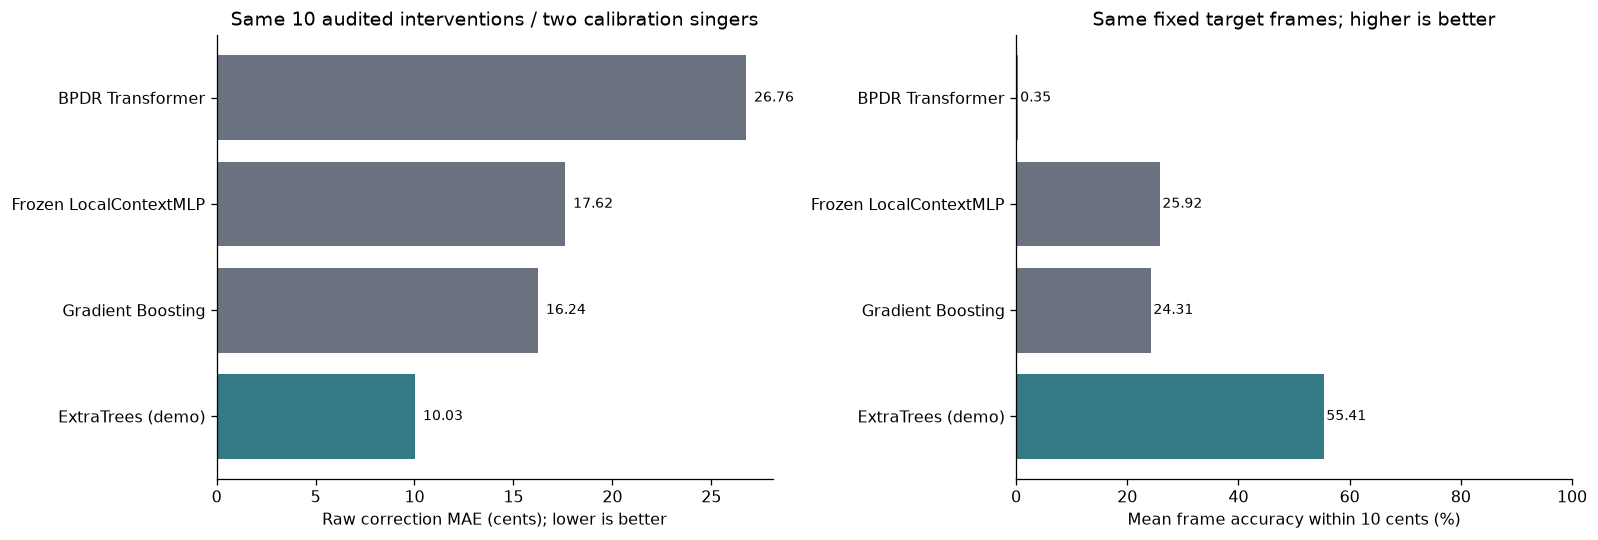

In [43]:
# MODEL-ACCURACY-5
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
labels = MODEL_ACCURACY.model.str.replace('Historical BPDR ', '').str.replace('Histogram Gradient Boosting', 'Gradient Boosting')
positions = np.arange(len(labels))
bar_colors = [COLORS['output'] if 'ExtraTrees' in label else COLORS['neutral'] for label in labels]
axes[0].barh(positions, MODEL_ACCURACY.raw_MAE_cents, color=bar_colors)
axes[0].set_yticks(positions, labels)
axes[0].invert_yaxis()
axes[0].set(xlabel='Raw correction MAE (cents); lower is better', title='Same 10 audited interventions / two calibration singers')
axes[1].barh(positions, MODEL_ACCURACY.accuracy_within_10c_percent, color=bar_colors)
axes[1].set_yticks(positions, labels)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 100)
axes[1].set(xlabel='Mean frame accuracy within 10 cents (%)', title='Same fixed target frames; higher is better')
for ax, values in [(axes[0], MODEL_ACCURACY.raw_MAE_cents), (axes[1], MODEL_ACCURACY.accuracy_within_10c_percent)]:
    for i, value in enumerate(values):
        ax.text(value + 0.4, i, f'{value:.2f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

<a id="MODEL-GATES"></a>
### `MODEL-GATES` · Every singer criterion and failed acceptance decision

In [44]:
# MODEL-GATES
criterion_rows = []
for stage, summary in [('calibration', LOCK['summary']), ('pilot', EVIDENCE['outer'])]:
    all_singers = sorted(groups['calibration' if stage == 'calibration' else 'pilot_evaluation'])
    for singer in all_singers:
        g = summary.get('by_group', {}).get(singer)
        if g is None:
            criterion_rows.append(dict(stage=stage, singer=singer, criterion='Measurable controlled labels', required='present', observed='no valid labels', passes=False))
            continue
        checks = [('Permitted correction gain', '> 0', g['permitted_correction_gain'], g['permitted_correction_gain'] > 0), ('Response gain', '>= 0.10', g['permitted_response_gain'], g['permitted_response_gain'] >= 0.1), ('Raw original mean absolute proposal', '<= 3 cents', g['raw_original_abs_mean'], g['raw_original_abs_mean'] <= 3), ('Permitted original mean absolute edit', '<= 1 cent', g['permitted_original_abs_mean'], g['permitted_original_abs_mean'] <= 1), ('Edited original frame fraction', '<= 0.05', g['original_edit_frame_fraction'], g['original_edit_frame_fraction'] <= 0.05), ('Permitted coverage over ALL attempts', '>= 0.25', g['all_attempt_permitted_coverage'], g['all_attempt_permitted_coverage'] >= 0.25)]
        for name, required, observed, passed in checks:
            criterion_rows.append(dict(stage=stage, singer=singer, criterion=name, required=required, observed=observed, passes=passed))
CRITERIA = pd.DataFrame(criterion_rows)
show(CRITERIA)

,stage,singer,criterion,required,observed,passes
0,calibration,female5,Permitted correction gain,> 0,0.2786,True
1,calibration,female5,Response gain,>= 0.10,0.2321,True
2,calibration,female5,Raw original mean absolute proposal,<= 3 cents,4.8365,False
3,calibration,female5,Permitted original mean absolute edit,<= 1 cent,0.0000,True
4,calibration,female5,Edited original frame fraction,<= 0.05,0.0000,True
5,calibration,female5,Permitted coverage over ALL attempts,>= 0.25,0.3750,True
6,calibration,male5,Permitted correction gain,> 0,0.0000,False
7,calibration,male5,Response gain,>= 0.10,0.0000,False
8,calibration,male5,Raw original mean absolute proposal,<= 3 cents,2.8062,True
9,calibration,male5,Permitted original mean absolute edit,<= 1 cent,0.0000,True


<a id="TREE-IMPORTANCE"></a>
### `TREE-IMPORTANCE` · Saved tree complexity, fitting cost and descriptive feature importance

In [35]:
# Code block: TREE-IMPORTANCE
importance = ESTIMATOR.feature_importances_
assert len(importance) == len(FEATURE_NAMES) == 31 and np.isclose(importance.sum(), 1.0)
importance_table = pd.DataFrame(dict(feature=FEATURE_NAMES, impurity_importance=importance)).sort_values('impurity_importance')
show(importance_table.iloc[::-1])

,feature,impurity_importance
16,residual_mean_31,0.1979
11,residual_mean_11,0.1582
24,pitch_minus_median_121,0.0891
2,residual_sine,0.0825
25,residual_minus_median_121,0.0497
26,residual_mean_121,0.0436
28,voiced_coverage_121,0.0381
23,voiced_coverage_61,0.0321
29,endpoint_contour_residual,0.0285
12,residual_spread_11,0.0280


<a id="TREE-IMPORTANCE-2"></a>
#### Visualize the result

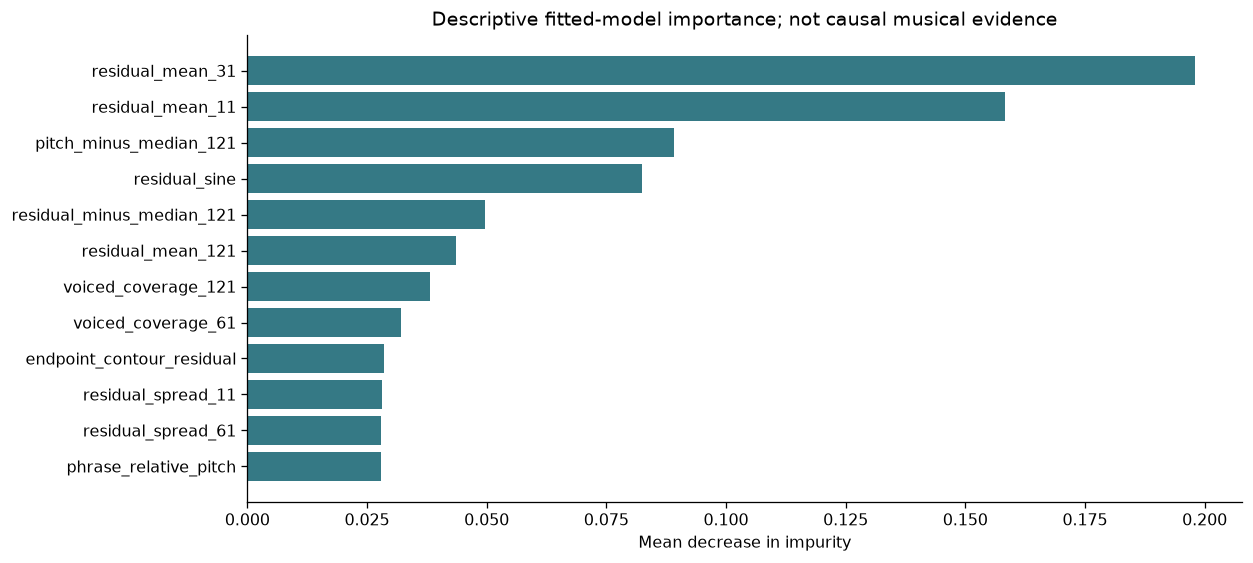

In [36]:
# Code block: TREE-IMPORTANCE-2
fig, ax = plt.subplots(figsize=(11, 5))
top = importance_table.tail(12)
ax.barh(top.feature, top.impurity_importance, color=COLORS['output'])
ax.set(xlabel='Mean decrease in impurity', title='Descriptive fitted-model importance; not causal musical evidence')
plt.tight_layout()
plt.show()